# Smart Water Quality Monitoring & Potability Prediction Using Logistic Regression

## 1. Introduction

Water quality is an important factor in public health and environmental sustainability. Access to safe drinking water requires monitoring different physical and chemical properties of water, such as pH, hardness, dissolved solids, conductivity, and turbidity.

With the development of Internet of Things (IoT) technologies, water quality parameters can be monitored using sensors and analyzed through machine learning techniques.

In this project, **Logistic Regression** is used to develop a binary classification model that predicts whether a water sample is potable or non-potable based on its measured water quality parameters.

The project combines data analytics, machine learning, and IoT-based water quality monitoring concepts.

## 2. Problem Statement

Evaluating water quality involves analyzing multiple physical and chemical parameters. Manually interpreting these parameters can be time-consuming.

The objective of this project is to develop a machine learning model that uses water quality measurements to classify water samples into two categories:

- **Potable (1):** Water classified as suitable for drinking.
- **Non-Potable (0):** Water classified as unsuitable for drinking.

Logistic Regression is selected because it is a supervised machine learning algorithm designed for binary classification and provides interpretable prediction probabilities.

## 3. Project Objectives

1. Analyze water quality data using Exploratory Data Analysis (EDA).
2. Identify and handle missing values and other data quality issues.
3. Investigate relationships between water quality parameters and potability.
4. Develop a binary Logistic Regression classification model.
5. Evaluate model performance using appropriate classification metrics.
6. Interpret model coefficients and understand the influence of input features.
7. Explore the potential application of the model in an IoT-based water quality monitoring system.

## 4. Project Scope

This project focuses on binary classification using Logistic Regression. Multinomial classification and other machine learning algorithms are outside the scope of this implementation.

```
The main objective of this project is to practice logistic regression (binary classification) only, not to achieve high accuracy
```

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [24]:
df = pd.read_csv('water_potability.csv')
# display first 5 rows
df.head(5)

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,NaN,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,NaN,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0


## 5. Dataset Collection

The dataset used in this project is the **Water Potability Dataset**, publicly available on Kaggle.

### 5.1 Feature Description

The dataset contains nine independent variables and one dependent variable.

**Independent Variables (X):**

| Feature | Description |
|---|---|
| ph | pH level of water |
| Hardness | Water hardness |
| Solids | Total dissolved solids |
| Chloramines | Chloramine concentration |
| Sulfate | Sulfate concentration |
| Conductivity | Electrical conductivity |
| Organic_carbon | Organic carbon concentration |
| Trihalomethanes | Trihalomethane concentration |
| Turbidity | Water cloudiness |

**Dependent Variable (Y):**

| Value | Description |
|---|---|
| 0 | Non-Potable |
| 1 | Potable |


In [25]:
# Check data types and null values
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3276 entries, 0 to 3275
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ph               2785 non-null   float64
 1   Hardness         3276 non-null   float64
 2   Solids           3276 non-null   float64
 3   Chloramines      3276 non-null   float64
 4   Sulfate          2495 non-null   float64
 5   Conductivity     3276 non-null   float64
 6   Organic_carbon   3276 non-null   float64
 7   Trihalomethanes  3114 non-null   float64
 8   Turbidity        3276 non-null   float64
 9   Potability       3276 non-null   int64  
dtypes: float64(9), int64(1)
memory usage: 256.1 KB


In [26]:
# check number of rows and columns
df.shape

(3276, 10)

In [27]:
# Identifying missing values
df.isnull().sum()

ph                 491
Hardness             0
Solids               0
Chloramines          0
Sulfate            781
Conductivity         0
Organic_carbon       0
Trihalomethanes    162
Turbidity            0
Potability           0
dtype: int64

In [28]:
# Identifying duplicate records.
df.duplicated().sum()

np.int64(0)

In [29]:
# Statistical Summary
df.describe()

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
count,2785.000000,3276.000000,3276.000000,3276.000000,2495.000000,3276.000000,3276.000000,3114.000000,3276.000000,3276.000000
mean,7.080795,196.369496,22014.092526,7.122277,333.775777,426.205111,14.284970,66.396293,3.966786,0.390110
std,1.594320,32.879761,8768.570828,1.583085,41.416840,80.824064,3.308162,16.175008,0.780382,0.487849
min,0.000000,47.432000,320.942611,0.352000,129.000000,181.483754,2.200000,0.738000,1.450000,0.000000
25%,6.093092,176.850538,15666.690297,6.127421,307.699498,365.734414,12.065801,55.844536,3.439711,0.000000
50%,7.036752,196.967627,20927.833607,7.130299,333.073546,421.884968,14.218338,66.622485,3.955028,0.000000
75%,8.062066,216.667456,27332.762127,8.114887,359.950170,481.792304,16.557652,77.337473,4.500320,1.000000
max,14.000000,323.124000,61227.196008,13.127000,481.030642,753.342620,28.300000,124.000000,6.739000,1.000000


## 6. Data Cleaning and Preprocessing

Data preprocessing is an important step in machine learning because the quality of input data can influence model performance.

This section focuses on identifying and handling missing values, duplicate records, and other data quality issues.

### 6.1 Handling Missing Values

The dataset contains missing values in some water quality parameters, particularly pH, Sulfate, and Trihalomethanes.

Missing values will be handled using median imputation. The median is selected because it is less sensitive to extreme values compared with the mean.



In [30]:
# fill null values in pH column with its median
df['ph'] = df['ph'].fillna(value=df['ph'].median())

In [31]:
# fill null values in Sulfate column with its median
df['Sulfate'] = df['Sulfate'].fillna(value=df['Sulfate'].median())

In [32]:
# fill null values in Trihalomethanes column with its median
df['Trihalomethanes'] = df['Trihalomethanes'].fillna(value=df['Trihalomethanes'].median())

In [33]:
# check missing/null values again
df.isnull().sum()

ph                 0
Hardness           0
Solids             0
Chloramines        0
Sulfate            0
Conductivity       0
Organic_carbon     0
Trihalomethanes    0
Turbidity          0
Potability         0
dtype: int64

### 6.2 Handling Duplicate Records

Duplicate records will be identified and investigated. If exact duplicate observations are found, they will be removed before model development.


In [34]:
# check duplicate records again
df.duplicated().sum()

np.int64(0)

### 6.3 Handling Outliers

Boxplots will be used to investigate potential outliers.

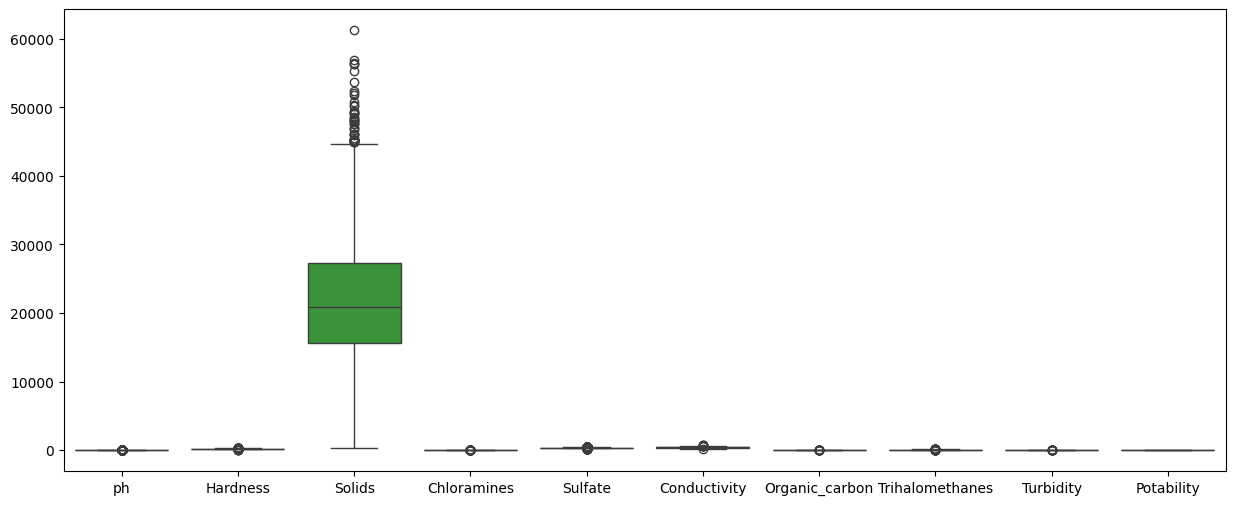

In [38]:
# visualize boxplot to check outliers
plt.figure(figsize=(15,6))
sns.boxplot(data=df)
plt.show()

In [42]:
# Remove outliers using IQR method through loop
for col in df.columns:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    min_range = q1 - (1.5*iqr)
    max_range = q3 + (1.5*iqr)
    df = df[(df[col] >= min_range) & (df[col] <= max_range)]

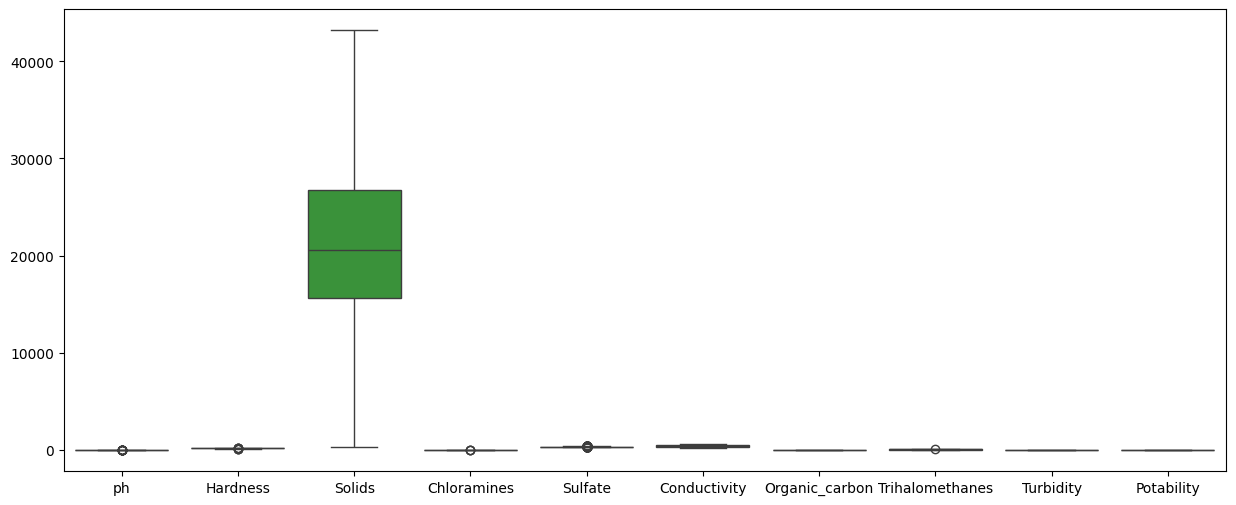

In [43]:
# visualize boxplot to check outliers again
plt.figure(figsize=(15,6))
sns.boxplot(data=df)
plt.show()

## 7. Exploratory Data Analysis (EDA)

Exploratory Data Analysis is performed to understand the distribution, characteristics, and relationships between different water quality parameters.

EDA helps identify patterns, potential outliers, class imbalance, and relationships that may influence water potability.


### 7.1 Target Variable Distribution

The distribution of the target variable, Potability, is analyzed to understand the number of potable and non-potable water samples.

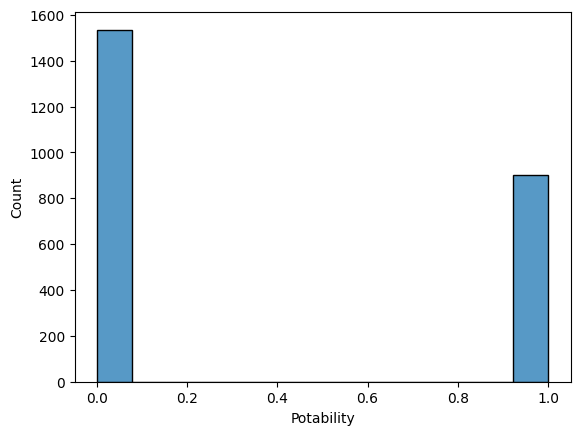

In [47]:
# distribution of target variable

sns.histplot(df['Potability'])
plt.show()

### 7.2 Pairplot Distributions

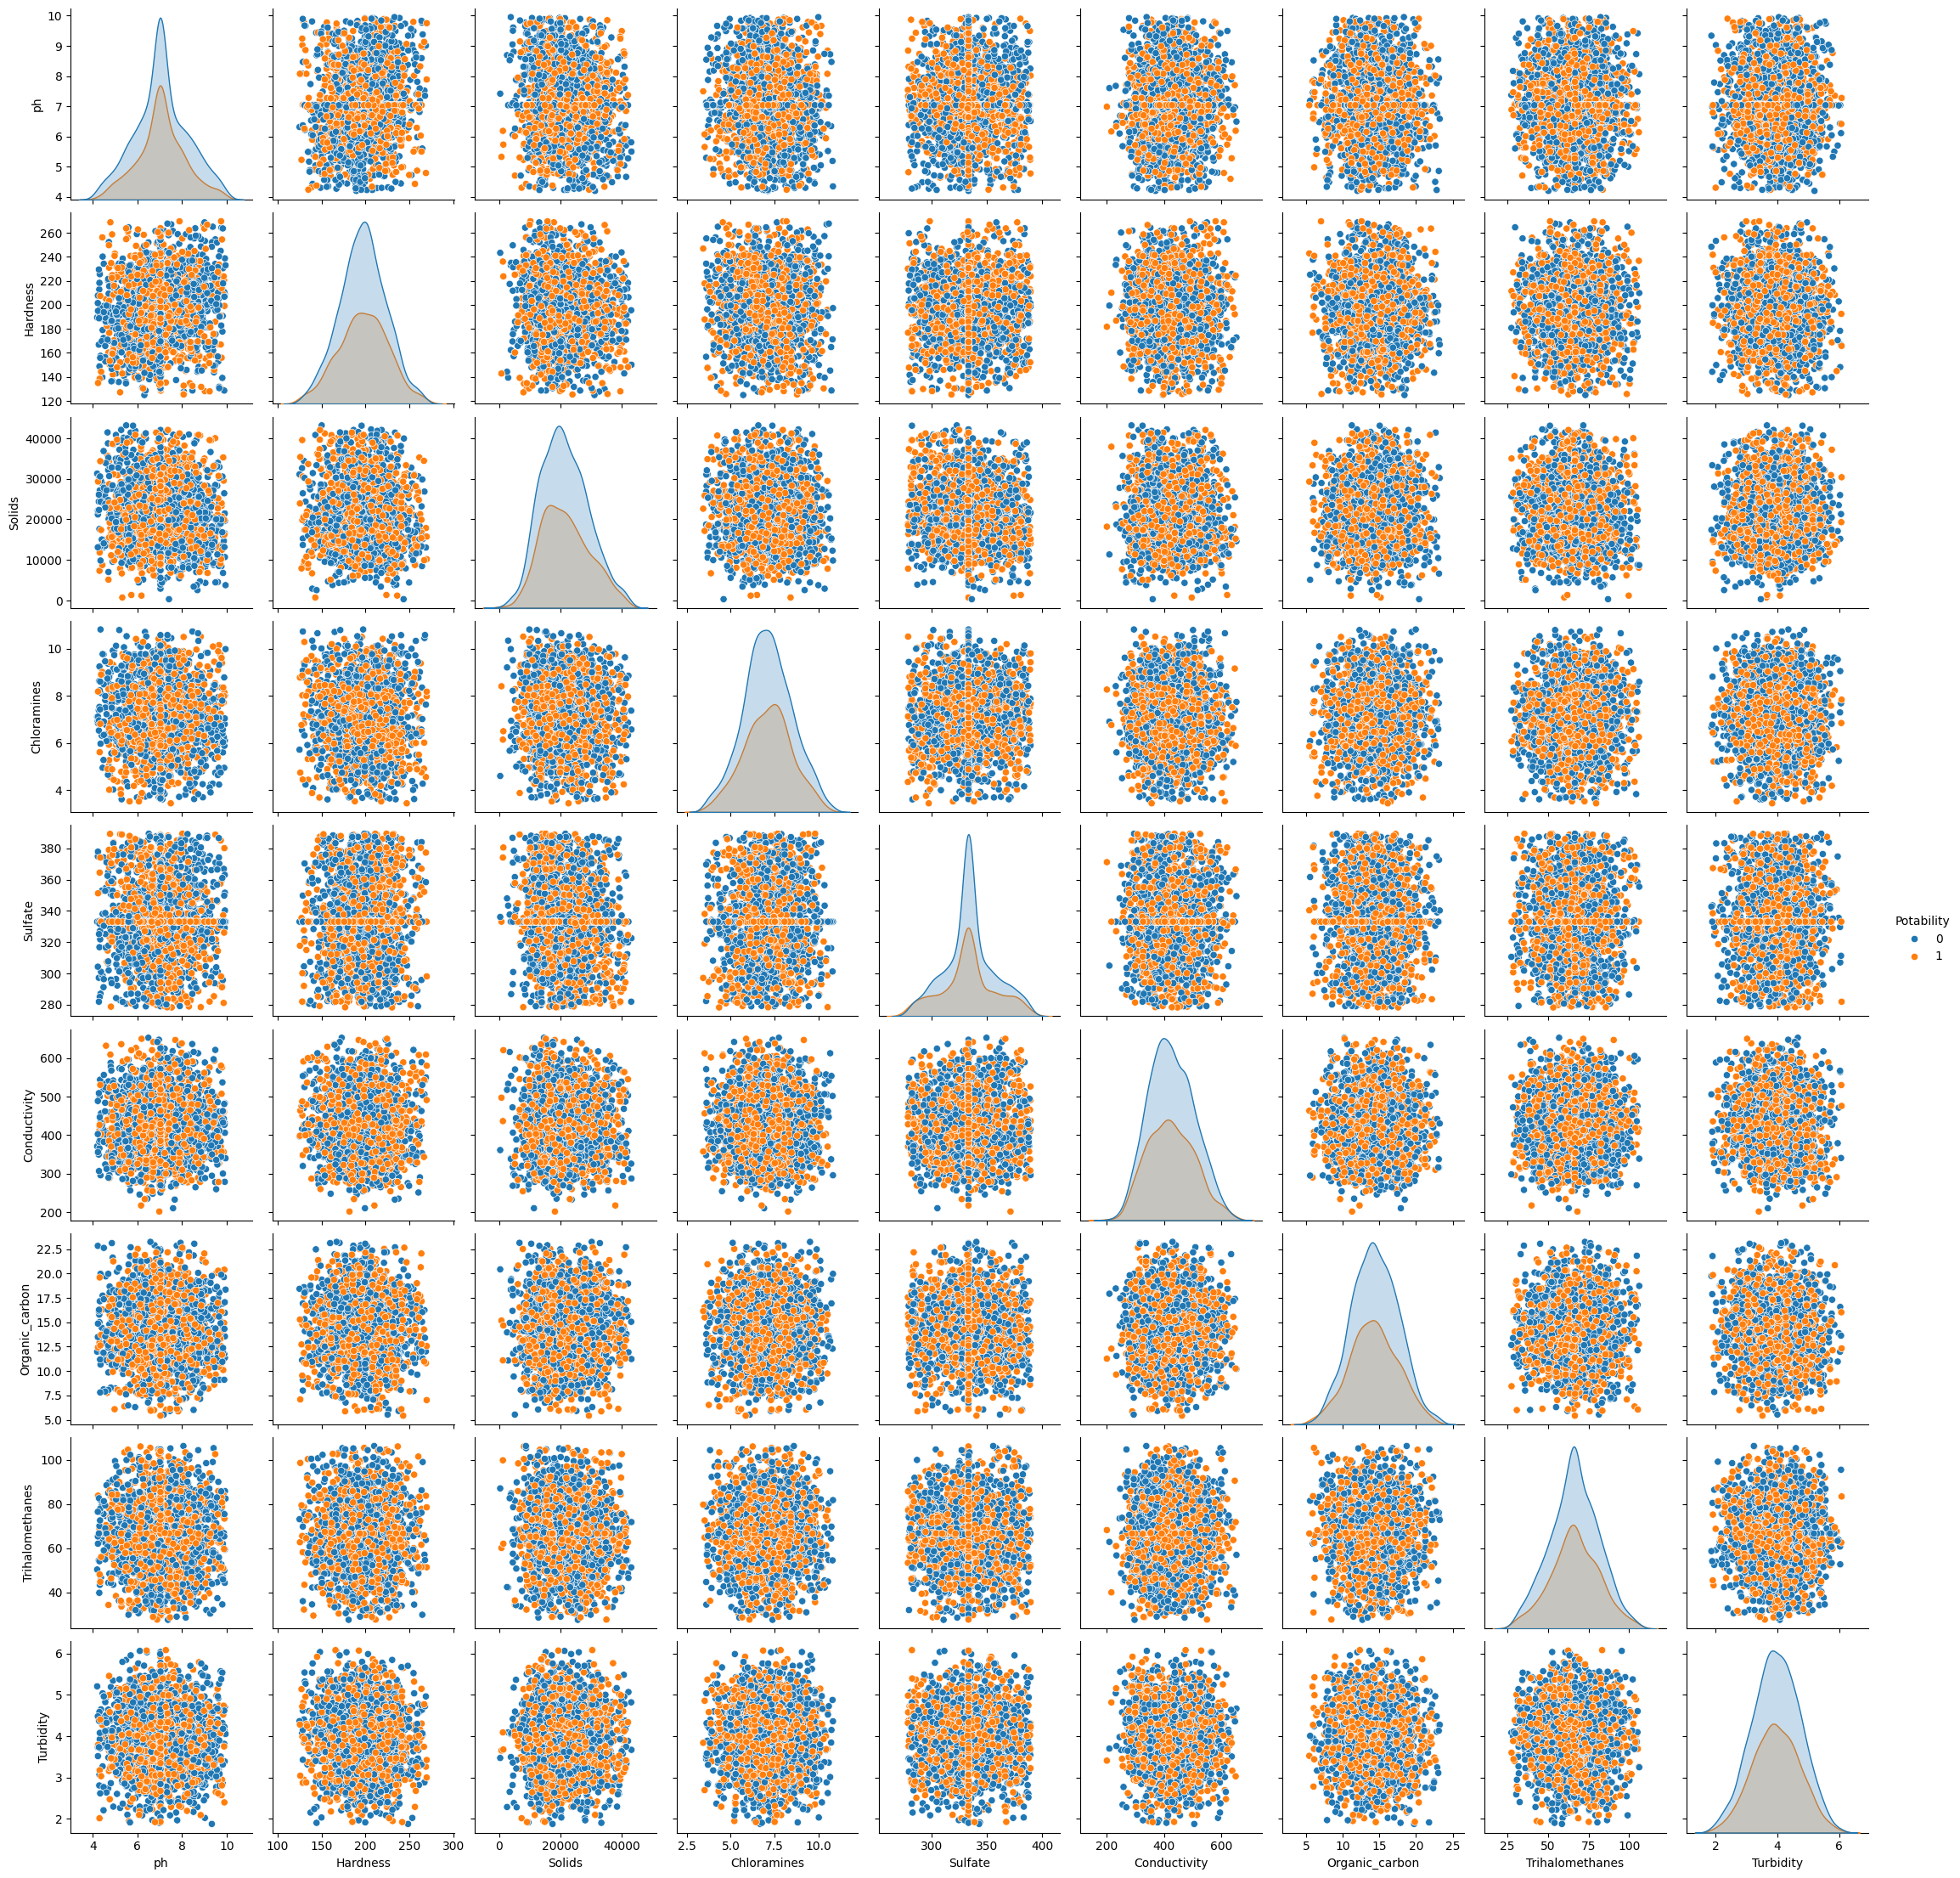

In [51]:
sns.pairplot(data=df, hue='Potability')
plt.show()

### 7.3 Correlation Analysis
A correlation heatmap is used to examine linear relationships between independent variables and the target variable.

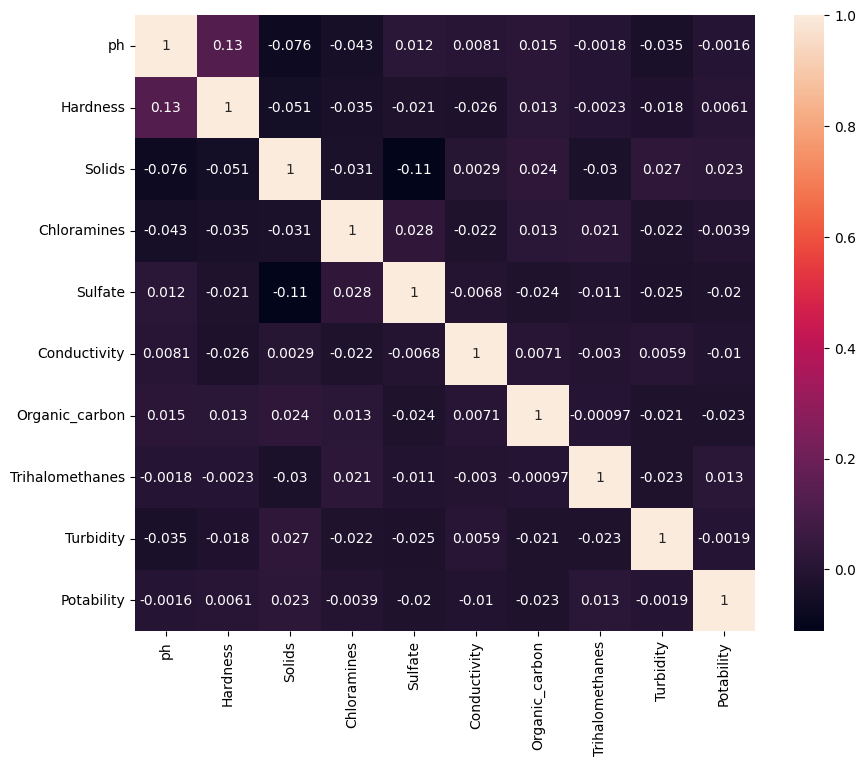

In [57]:
plt.figure(figsize=(10,8))
sns.heatmap(df.corr(), annot=True)
plt.show()

## 8. Feature Selection and Dataset Splitting

The dataset is divided into independent variables (X) and the dependent variable (y).

The nine water quality parameters are used as input features, while Potability is selected as the target variable.

### 8.1 Defining Input and Target Variables

- **X:** Nine independent water quality parameters.
- **y:** Potability (0 = Non-Potable, 1 = Potable).

### 8.2. Feature Scaling and Preprocessing

The water quality parameters have different measurement scales. For example, Solids and Hardness have considerably larger numerical values than pH and Turbidity.

Feature standardization is therefore applied to bring the numerical features onto a comparable scale.

**StandardScaler** transforms each feature by subtracting its mean and dividing by its standard deviation.

Missing values are handled using median imputation before standardization.

Both preprocessing operations are implemented inside a Scikit-learn Pipeline to prevent data leakage.

### 8.3 Train-Test Splitting

The dataset is divided into training and testing sets using an 80:20 ratio.

- Training data (80%): Used to train the Logistic Regression model.
- Testing data (20%): Used to evaluate the model on unseen observations.

Stratified sampling is applied to maintain approximately the same target class proportions in both subsets.

A fixed random state is used to make the results reproducible.

In [80]:
x = df.iloc[:,:-1]
y = df['Potability']

In [60]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

In [61]:
sc = StandardScaler()
sc.fit(x)
X = pd.DataFrame(sc.transform(x), columns= x.columns)

In [62]:
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## 9. Logistic Regression Model Development

Logistic Regression is a supervised machine learning algorithm used for binary classification.

Unlike linear regression, Logistic Regression estimates the probability that an observation belongs to a particular class.

The sigmoid function converts the model's linear output into a probability between 0 and 1.

The classification decision is initially made using a threshold of 0.5:

- Probability ≥ 0.5: Potable (1).
- Probability < 0.5: Non-Potable (0).

The model uses all nine water quality parameters to estimate the probability of water potability.

### 9.1 Model Training

The Logistic Regression model is trained using the training dataset after applying missing-value imputation and feature standardization.

### 9.2 Model Prediction

After training, the model generates class predictions and probability estimates for the testing dataset.

In [63]:
from sklearn.linear_model import LogisticRegression

In [64]:
lr = LogisticRegression()
lr.fit(x_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default sol

In [65]:
lr.score(x_test, y_test)

0.6168032786885246